# LFAST ETC quickstart

`lfast_etc` is an exposure time calculator for the LFAST telescope array at Kitt Peak
(nominally 20 x 0.726 m unit telescopes feeding one spectrograph through an 18 um fiber combiner).
Two instruments are modelled: the **WIYN Bench** spectrograph (visible, R ~ 1800 sample
configuration) and **CSHELL** (1.08-1.75 um, R = 18,000 / 21,500 / 43,000).

Everything is computed **per resolution element**: for each wavelength bin of width
$\delta\lambda = \lambda/R$ the star gives $N_*$ e$^-$/s inside the bin (summed over the array),
the sky gives $N_{sky}$ e$^-$/s/pixel, and with $n_{pix}$ pixels per resel, dark current $D$,
read noise $RN$ and $n_{exp}$ reads of total length $t$:

$$\mathrm{SNR} = \frac{N_* t}{\sqrt{N_* t + n_{pix}(N_{sky} + D)\,t + n_{pix}\, n_{exp}\, RN^2}}$$

The throughput model follows Choi et al. (2026, SPIE 14147). This notebook reproduces the
reference LFAST ETC notebook (2026-10-12) and shows the main API.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from lfast_etc import LFASTETC, Source, Telescope, Instrument, list_instruments
from lfast_etc.plotting import plot_snr_map, plot_limiting_magnitude
try:
    plt.style.use('gks')
except OSError:
    pass

## Build an ETC

Pick an instrument preset and the number of telescopes.

In [2]:
print(list_instruments())
etc = LFASTETC("bench_r1800", n_telescopes=20)
etc

['bench_r1800', 'cshell_r18000', 'cshell_r21500', 'cshell_r43000']


LFASTETC(bench_r1800: R=1800, 412-686 nm, 2.2 pix/resel, S_opt=0.3, slit=1.0, RN=3.7 e-, dark=0.0003 e-/s/pix | 20 x 0.726 m telescopes (total area 8.28 m^2), 18um fiber (1.48" on sky), combine=fiber | SkyCalc table skytable_secz1.3.fits x 1, 918 bins)

## Define a source

Sources are an SED shape plus one magnitude. Spectral lines can be injected as Gaussians; they are averaged over each resolution element (equivalent width preserved), so a 0.05 nm line on a 0.36 nm resel shows up as a shallower, resel-wide dip.

In [3]:
src = Source.blackbody(5800, mag=15, band="V").add_line(656.3, depth=0.3, sigma_nm=0.05)
print(src.describe(), "| synthetic J =", round(src.magnitude("J"), 2))

blackbody 5800 K, V=15.00 (Vega) | synthetic J = 13.85


## Exposure time to reach a target SNR per resel

{'snr': {10: np.float64(50.0), 50: np.float64(50.0), 90: np.float64(50.0)},
 'exptime': {10: np.float64(229.270496108288),
  50: np.float64(361.87619110806287),
  90: np.float64(925.6365694379806)},
 'saturated_fraction': 0.0,
 'below_min_exptime_fraction': 0.0,
 'n_bins': 918}

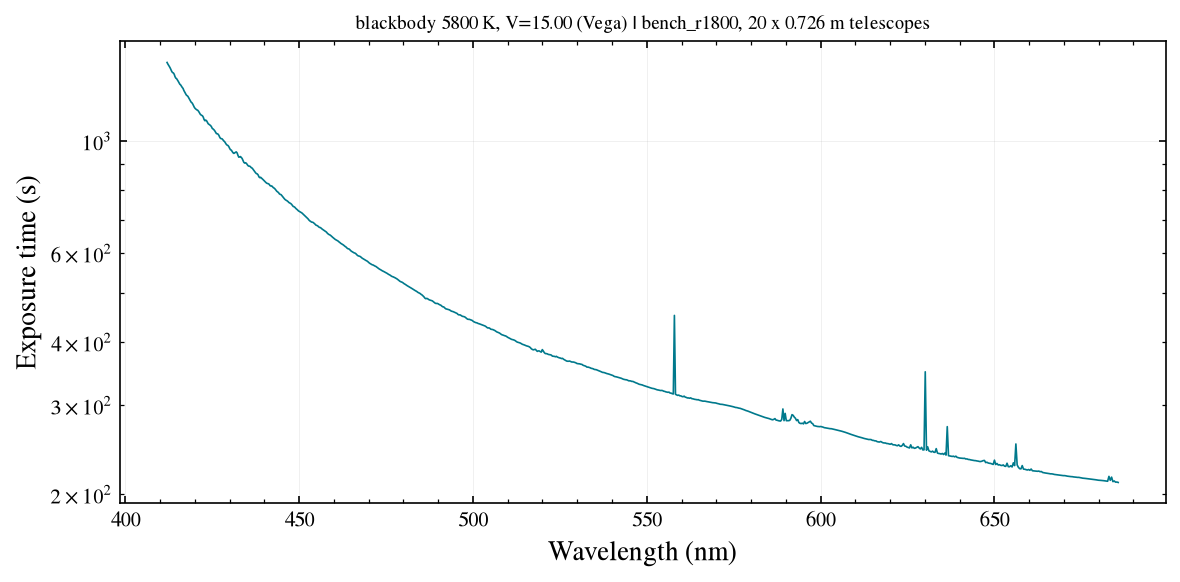

In [4]:
res = etc.exptime(src, snr=50)
res.plot()
res.summary()

The result object carries every per-bin quantity. Query one wavelength:

In [5]:
res.at(550.0)

{'snr': 50.0,
 'exptime': 327.0546789938435,
 'n_star': 7.942802011508906,
 'n_sky_pix': 0.09897765792143967,
 'peak_e_per_pixel': 1213.255499803103}

## SNR for a fixed exposure time

{10: np.float64(40.13745634502136),
 50: np.float64(64.52471608824618),
 90: np.float64(81.16898662069794)}

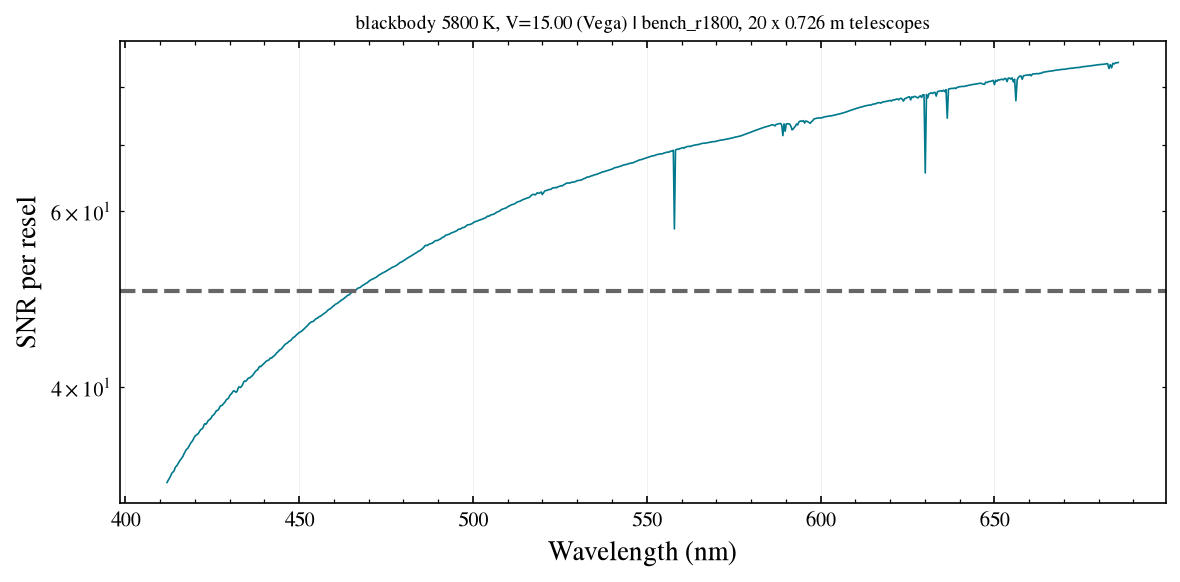

In [6]:
res = etc.snr(src, exptime=600)
ax = res.plot()
ax.axhline(50, color='0.4', ls='--')
res.summary()['snr']

## What limits us? Electron rates per pixel

Both star and sky are shown per pixel here (the star rate is $N_*/n_{pix}$). Note the bundled sky table is **grey time** (moon up, 45 deg away): scattered moonlight is ~60% of the visible sky; see the sensitivity-map notebook for a dark-time scaling.

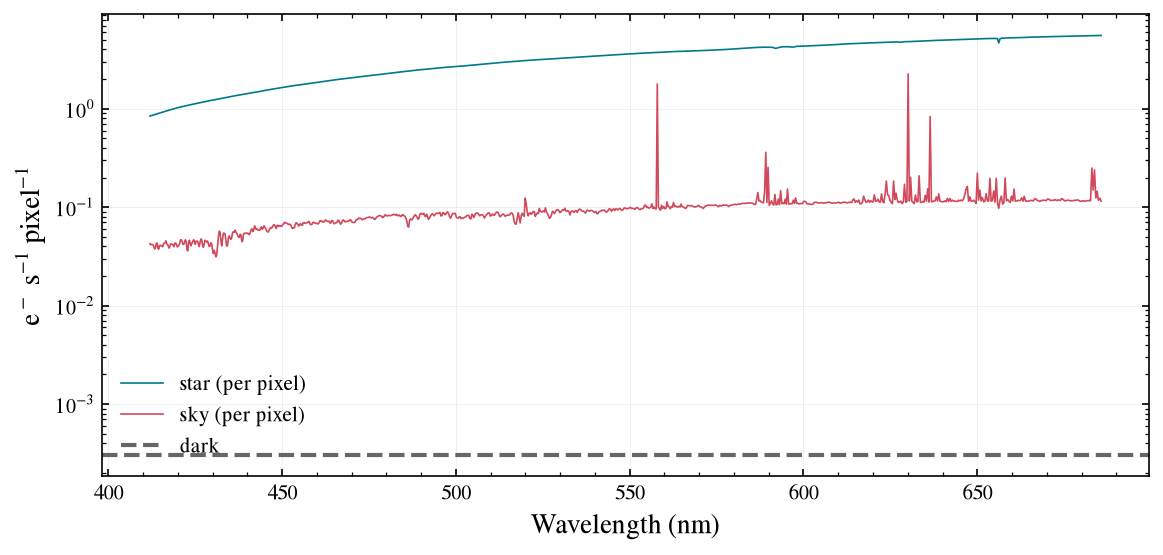

In [7]:
res.plot_rates();

## Switching instruments and overriding parameters

CSHELL's free spectral range is tiny (~2.5e-3 lambda, i.e. ~40 A at 1.55 um), so a single setting
covers one narrow window; restrict the grid accordingly. Any instrument field can be overridden
through `Instrument.from_preset(name, **overrides)` or `instrument.replace(...)`.

In [8]:
cshell = LFASTETC("cshell_r18000", wavelength_min_nm=1550, wavelength_max_nm=1554)
kstar = Source.blackbody(4500, mag=9, band="H")
r = cshell.snr(kstar, exptime=300)
print("CSHELL R=18k, H=9 K star, 300 s: median SNR/resel =", round(float(np.median(r.snr)), 1),
      "| peak e-/pix =", int(r.peak_e_per_pixel.max()), "| saturated:", r.saturated.any())

lowRN = Instrument.from_preset("cshell_r18000", read_noise=5.0)
r2 = LFASTETC(lowRN, wavelength_min_nm=1550, wavelength_max_nm=1554).snr(kstar, exptime=300)
print("same with RN = 5 e-:", round(float(np.median(r2.snr)), 1))

CSHELL R=18k, H=9 K star, 300 s: median SNR/resel = 72.8 | peak e-/pix = 4455 | saturated: False
same with RN = 5 e-: 78.5


## Scaling the array

The number of telescopes is a plain parameter. With the 18 um fibers all telescopes feed one
spectrograph input (`combine="fiber"`): signal and sky per pixel scale with $N$ while the detector
noise does not. The 50 um fiber does not go through the combiner, so each telescope delivers its
own spectrum (`combine="independent"`, SNR $\propto\sqrt{N}$).

In [9]:
faint = Source.blackbody(5800, mag=19, band="V")
for n in (1, 5, 20, 50):
    for fiber in ("18um", "50um"):
        e = LFASTETC("bench_r1800", telescope=Telescope(n_telescopes=n, fiber=fiber))
        t = e.exptime(faint, snr=20)
        print(f"N={n:3d} {fiber}: median t(SNR=20) = {np.median(t.exptime)/60:7.1f} min  [{e.telescope.combine}]")

N=  1 18um: median t(SNR=20) =  1623.1 min  [fiber]
N=  1 50um: median t(SNR=20) =  1656.9 min  [independent]
N=  5 18um: median t(SNR=20) =   316.1 min  [fiber]
N=  5 50um: median t(SNR=20) =   335.7 min  [independent]
N= 20 18um: median t(SNR=20) =    78.6 min  [fiber]
N= 20 50um: median t(SNR=20) =    87.3 min  [independent]
N= 50 18um: median t(SNR=20) =    31.4 min  [fiber]
N= 50 50um: median t(SNR=20) =    37.4 min  [independent]


## Your own spectrum

Any `(wavelength_nm, flux)` arrays work; the magnitude sets the absolute scale.

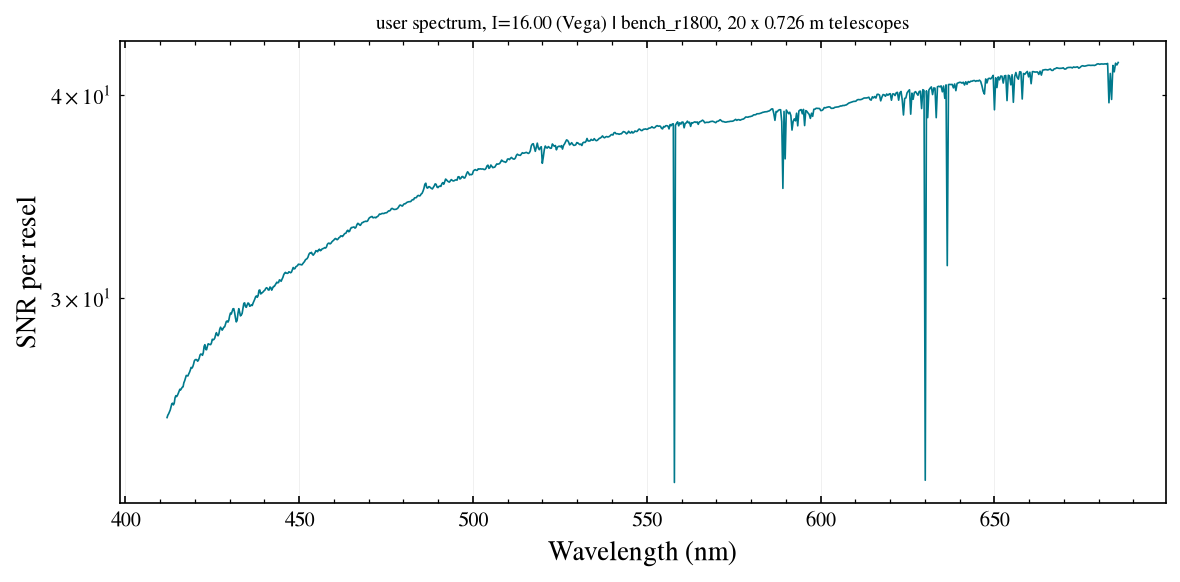

In [10]:
wl = np.linspace(380, 1800, 3000)
flux = wl**-2 * (1 + 0.5*np.exp(-0.5*((wl-850)/20)**2))   # F_nu-flat continuum with a bump
user = Source.from_arrays(wl, flux, flux_unit="flam", mag=16, band="I")
r = LFASTETC("bench_r1800").snr(user, 900)
r.plot();